# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Camello, Zack Kenshin)_:
- _Student No._: 2024-08825
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

## Report figure

### Problem 1
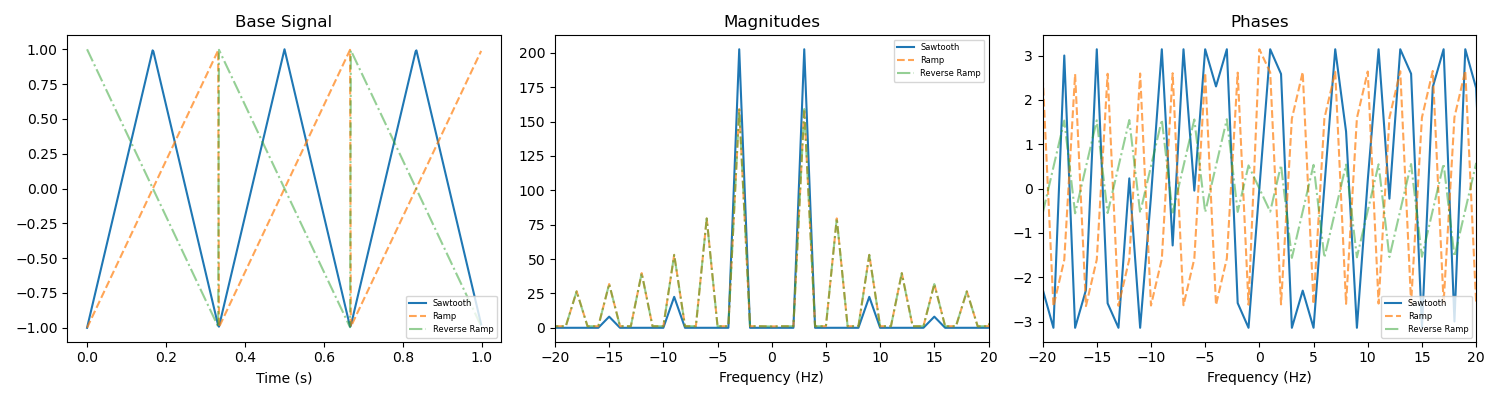

### Problem 2
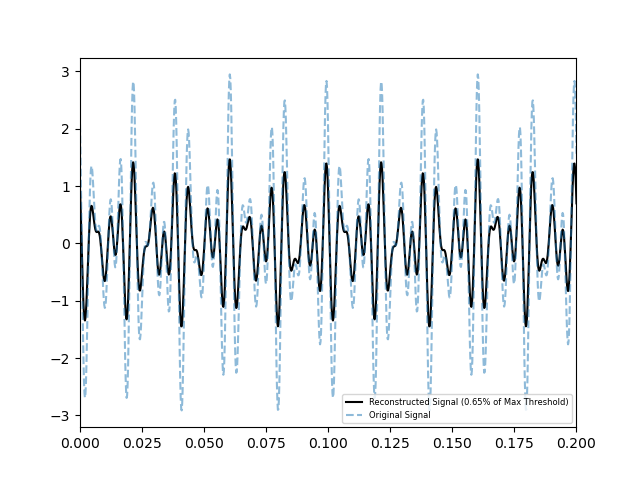

### Problem 3
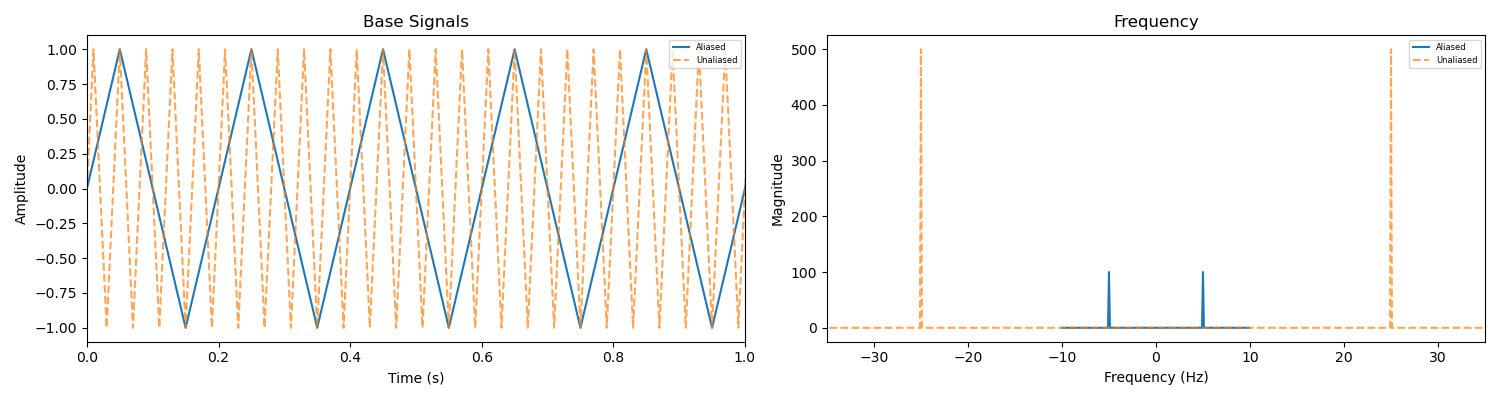

## Report discussion

Problem 1:
-  Changing the shape of the input signal changes the distribution of frequencies within the wave, thus affecting the resulting Fourier transform magnitude and phase. For example, altering a sawtooth wave into a ramp changes the phase distribution in which the phase angles become inverted.

Problem 2: 
- Lowering the number of points (N) reduces the resolution of the signal and struggles to fully capture its higher frequency components. Because of this, recovering the original signal becomes difficult or outright impossible below a certain threshold, as the data lacks the necessary detail. Simply put, if N is too low, the sampling interval becomes too wide to accurately capture the fine fluctuations required to cleanly reconstruct the signal. 

Problem 3:
- The figure above shows the difference between aliased (sufficient) and unaliased (insufficient) sampling rates. With an unaliased signal, the true frequency of 25 Hz was captured. In comparison, the aliased waveform suffered from under-sampling, causing the high-frequency to fold back and falsely appear as a peak at $\pm 5\text{ Hz}$.

## Other comments

---
## Section 2: Code

In [73]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

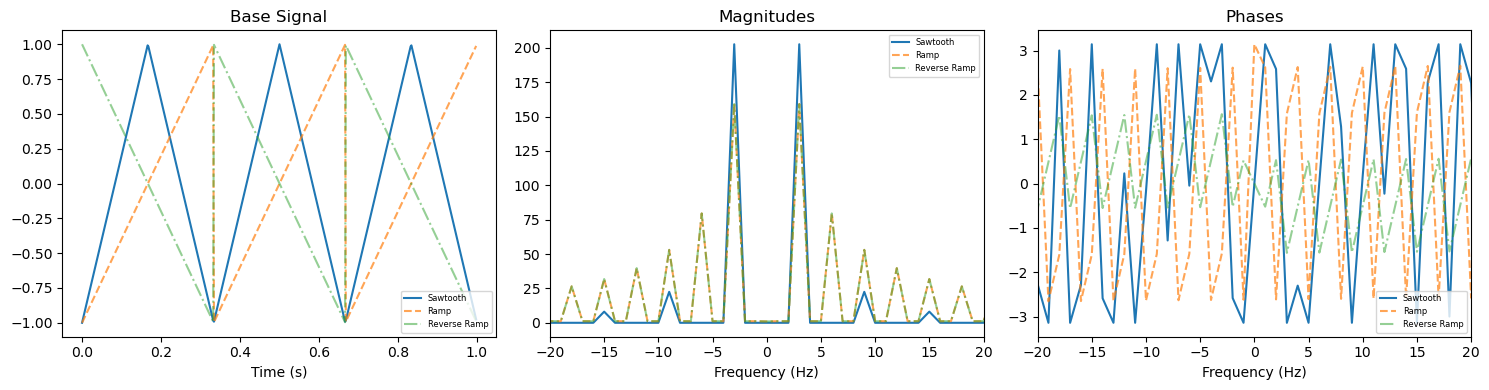

In [74]:
# Problem 1

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Determines how many points there are within our bounds to ensure the graphs are smooth
N_triangle = 500 
t_triangle = np.linspace(0, 1, N_triangle, endpoint = False) 
triangle_dt = t_triangle[1] - t_triangle[0]

# Generates the various signals
signal_freq = 3
sawtooth = signal.sawtooth(2 * np.pi * signal_freq * t_triangle, width = 0.5)
ramp = signal.sawtooth(2 * np.pi * signal_freq * t_triangle, width = 1)
reverse_ramp = signal.sawtooth(2 * np.pi * signal_freq * t_triangle, width = 0)

# Calculates Fourier Transform
sawtooth_fourier = np.abs(np.fft.fftshift(np.fft.fft(sawtooth)))
ramp_fourier = np.abs(np.fft.fftshift(np.fft.fft(ramp)))
reverse_ramp_fourier = np.abs(np.fft.fftshift(np.fft.fft(reverse_ramp)))

# Calculates Phases
sawtooth_phase = np.angle(np.fft.fftshift(np.fft.fft(sawtooth)))
ramp_phase = np.angle(np.fft.fftshift(np.fft.fft(ramp)))
reverse_ramp_phase = np.angle(np.fft.fftshift(np.fft.fft(reverse_ramp)))

# Calculates actual frequencies
freqs = np.fft.fftshift(np.fft.fftfreq(N_triangle, triangle_dt))

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(t_triangle, sawtooth, label="Sawtooth")
axes[0].plot(t_triangle, ramp, label="Ramp", linestyle = "--", alpha = 0.7)
axes[0].plot(t_triangle, reverse_ramp, label="Reverse Ramp", linestyle = "-.", alpha = 0.5)
axes[0].set_title("Base Signal")
axes[0].set_xlabel("Time (s)")
axes[0].legend(fontsize = 6, loc = "lower right")

axes[1].plot(freqs, sawtooth_fourier, label="Sawtooth")
axes[1].plot(freqs, ramp_fourier, label="Ramp", linestyle = "--", alpha = 0.7)
axes[1].plot(freqs, reverse_ramp_fourier, label="Reverse Ramp", linestyle = "-.", alpha = 0.5)
axes[1].set_title("Magnitudes")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_xlim(-20, 20) 
axes[1].legend(fontsize = 6, loc = "upper right")

axes[2].plot(freqs, sawtooth_phase, label="Sawtooth")
axes[2].plot(freqs, ramp_phase, label="Ramp", linestyle = "--", alpha = 0.7)
axes[2].plot(freqs, reverse_ramp_phase, label="Reverse Ramp", linestyle = "-.", alpha = 0.5)
axes[2].set_title("Phases")
axes[2].set_xlabel("Frequency (Hz)")
axes[2].set_xlim(-20, 20)
axes[2].legend(fontsize = 6, loc = "lower right")

plt.tight_layout()
plt.savefig("Problem 1")
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [75]:
# Problem 2
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]

signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

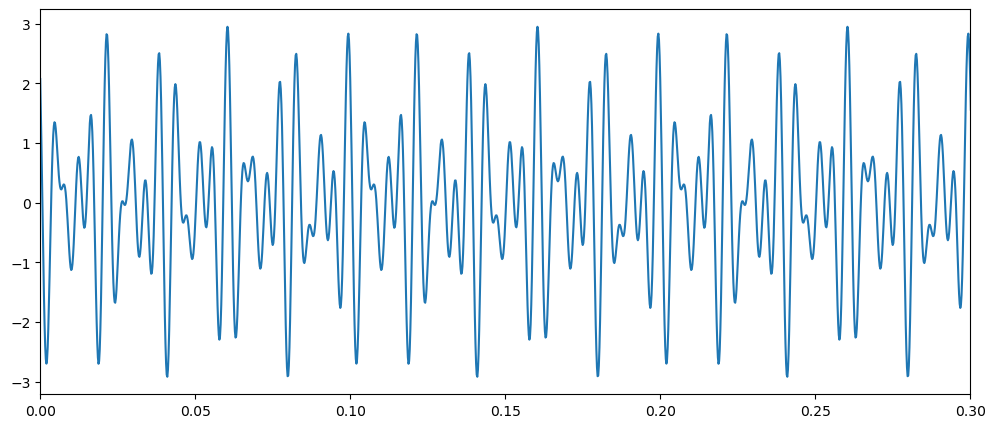

In [76]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)

FILL: Plot the fourier transform of the clean, original signal

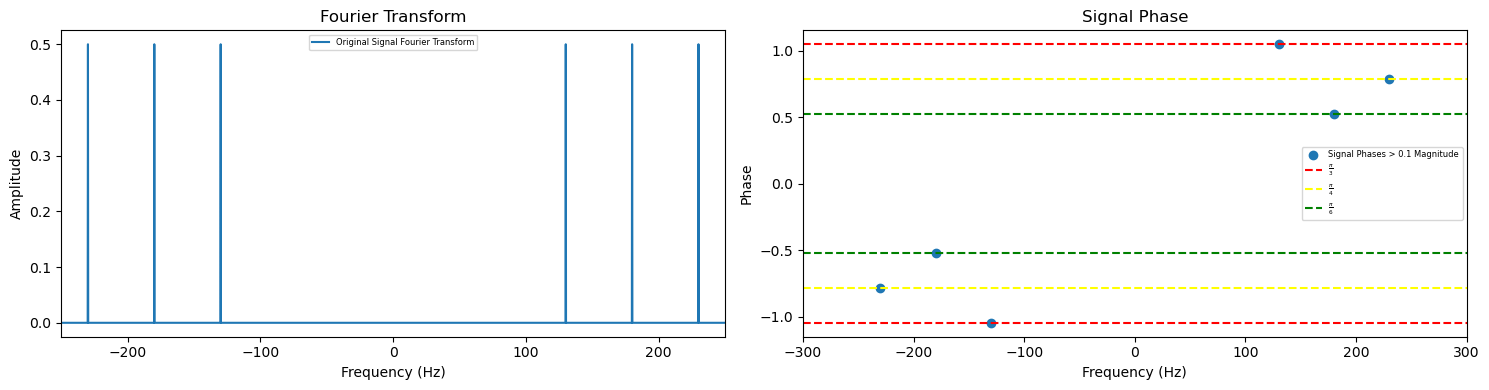

In [110]:
# Calculates Fourier Transform
original_fourier = np.abs(np.fft.fftshift(np.fft.fft(signal_original)))/N

# Calculates Phase
original_phase = np.angle(np.fft.fftshift(np.fft.fft(signal_original)))

# Calculates Frequency
original_freq = np.fft.fftshift(np.fft.fftfreq(N, dt))

# Filters out the noise which has amplitudes close to 0
filtered = original_fourier > 0.1

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

axes[0].plot(original_freq, original_fourier, label = "Original Signal Fourier Transform")
axes[0].set_title("Fourier Transform")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(-250, 250)
axes[0].legend(fontsize = 6, loc = "upper center")

axes[1].scatter(original_freq[filtered], original_phase[filtered], label = "Signal Phases > 0.1 Magnitude")
axes[1].axhline(y = np.pi/3, linestyle = "--", color = "red", label = f"$\\frac{{\\pi}}{{3}}$")
axes[1].axhline(y = np.pi/4, linestyle = "--", color = "yellow", label = f"$\\frac{{\\pi}}{{4}}$")
axes[1].axhline(y = np.pi/6, linestyle = "--", color = "green", label = f"$\\frac{{\\pi}}{{6}}$")
axes[1].axhline(y = -np.pi/3, linestyle = "--", color = "red")
axes[1].axhline(y = -np.pi/4, linestyle = "--", color = "yellow")
axes[1].axhline(y = -np.pi/6, linestyle = "--", color = "green")
axes[1].set_title("Signal Phase")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Phase")
axes[1].set_xlim(-300, 300)
axes[1].legend(fontsize = 6, loc = "center right")

plt.tight_layout()
plt.show()

In [111]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

(0.0, 0.2)

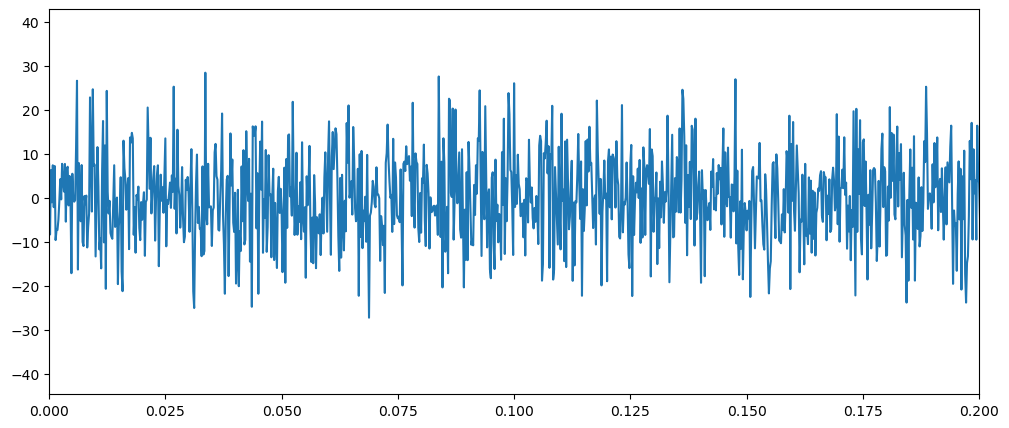

In [114]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.2)

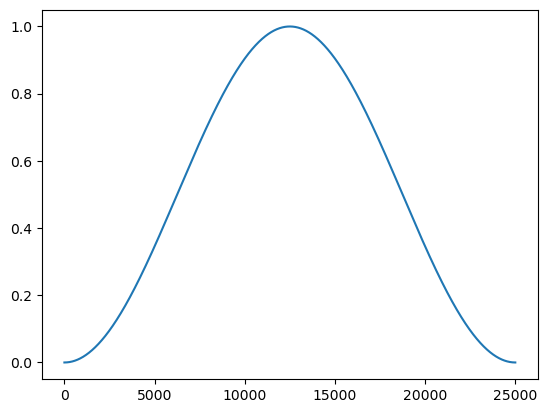

In [115]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)

In [116]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))


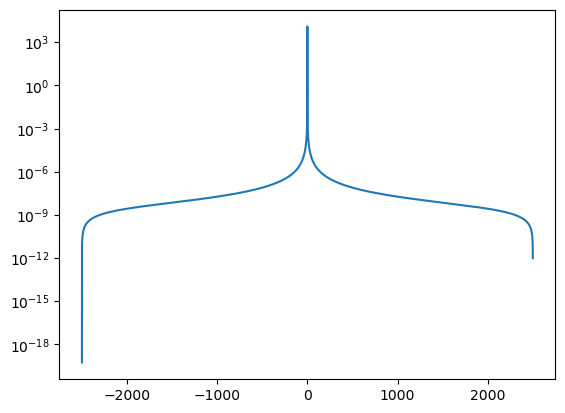

In [117]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [118]:
noisy_fourier = np.fft.fft(noisy_data*window)
noisy_magnitude = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))
noisy_freq = np.fft.fftshift(np.fft.fftfreq(N, dt))

Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

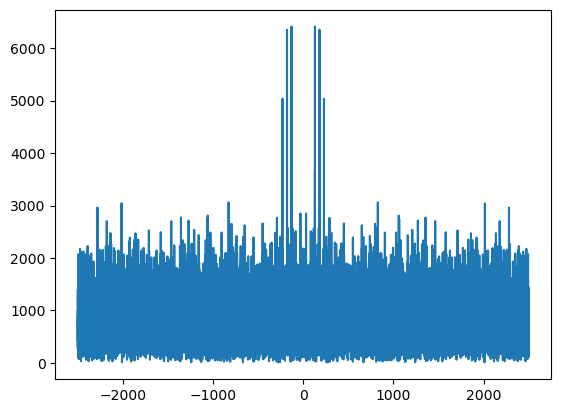

In [119]:
plt.plot(noisy_freq, noisy_magnitude)

Fill: Find a suitable threshold value to filter the noise in fourier space

In [120]:
threshold = 0.65 * np.max(np.abs(noisy_fourier)) # 0.64 < x < 0.9 keeps the resulting inverse transform of the same shape
filtered_noise = np.where(np.abs(noisy_fourier) > threshold, noisy_fourier, 0)

Fill: with the cleaned signal in fourier space, convert it back to the time domain

In [121]:
reconverted = np.real(np.fft.ifft(filtered_noise))

Plot the recovered signal

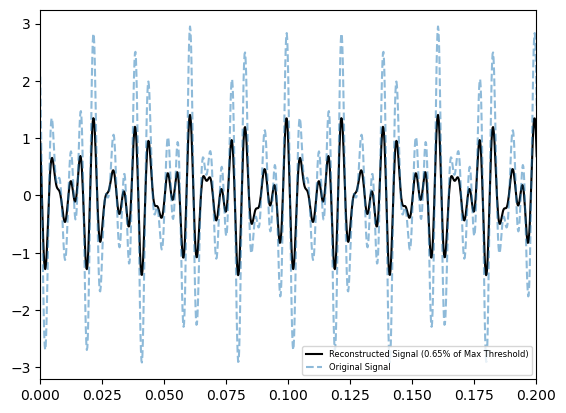

In [122]:
plt.figure()
plt.plot(t_, reconverted, label = "Reconstructed Signal (0.65% of Max Threshold)", alpha = 1, color = "black")
plt.plot(t_, signal_original, label = "Original Signal", linestyle = "--", alpha = 0.5)
plt.xlim(0, 0.2)
plt.legend(fontsize = 6, loc = "lower right")
plt.savefig("Problem 2")
plt.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

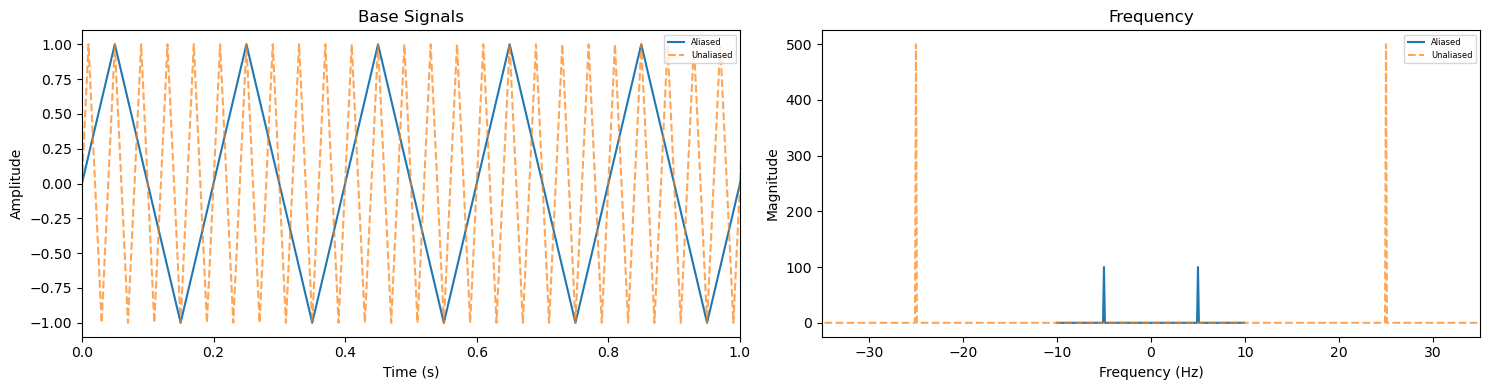

In [123]:
import numpy as np
import matplotlib.pyplot as plt

N_aliased = 200
N_unaliased = 1000
t = 10
aliased_dt = t / N_aliased
unaliased_dt = t / N_unaliased
t_aliased = np.arange(N_aliased) * aliased_dt
t_unaliased = np.arange(N_unaliased) * unaliased_dt

freq = 25 # Way past the limit of our aliased signal which samples at 20 per second while its highest presentable frequency is only 10)

# Function f our continuous signal
def sinu_signal(freq, time):
    return np.sin(2 * np.pi * freq * time)  # + np.sin(2 * np.pi * 3.5 * time)

# Creates 
discrete_aliased = sinu_signal(freq, t_aliased)
discrete_unaliased = sinu_signal(freq, t_unaliased)

four_aliased = np.abs(np.fft.fftshift(np.fft.fft(discrete_aliased)))
four_aliased_dt = np.fft.fftshift(np.fft.fftfreq(N_aliased, aliased_dt))
four_unaliased = np.abs(np.fft.fftshift(np.fft.fft(discrete_unaliased)))
four_unaliased_dt = np.fft.fftshift(np.fft.fftfreq(N_unaliased, unaliased_dt))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

axes[0].plot(t_aliased, discrete_aliased, label = "Aliased")
axes[0].plot(t_unaliased, discrete_unaliased, label = "Unaliased", linestyle = "--", alpha = 0.7)
axes[0].set_title("Base Signals")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(0, 1) 
axes[0].legend(fontsize = 6, loc = "upper right")

axes[1].plot(four_aliased_dt, four_aliased, label = "Aliased")
axes[1].plot(four_unaliased_dt, four_unaliased, label = "Unaliased", linestyle = "--", alpha = 0.7)
axes[1].set_xlim(-35, 35) 
axes[1].set_title("Frequency")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude")
axes[1].legend(fontsize = 6, loc = "upper right")

plt.tight_layout()
plt.savefig("Problem 3")
plt.show()

#### Problem code summary

The code simulates various signals and computes their Fast Fourier Transforms to analyze and determine their frequencies and phases. For one specific problem, noise is introduced and a threshold is applied to filter out said noise while preserving the dominant signals. Finally, the inverse Fourier transform is utilized to reconstruct the original non-noisy waveform. 

---
## Section 3: Notes

In [15]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

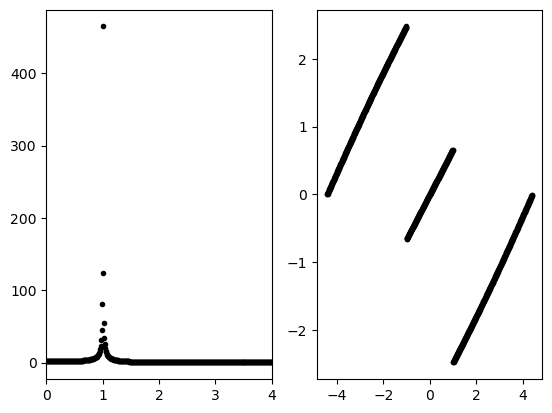

In [16]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [17]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

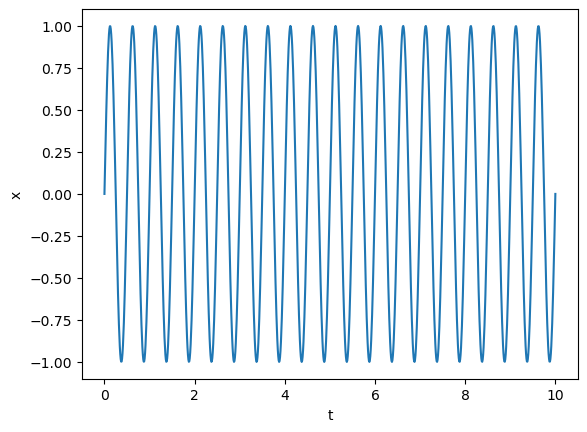

In [18]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [19]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

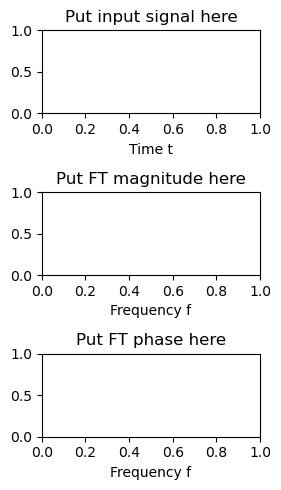

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

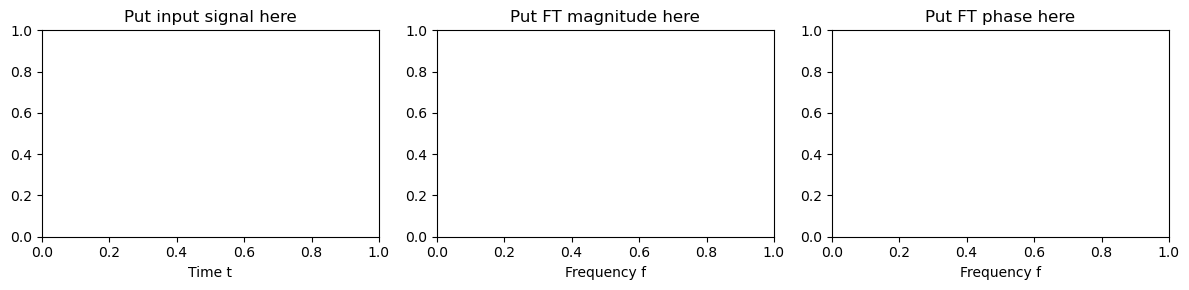

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

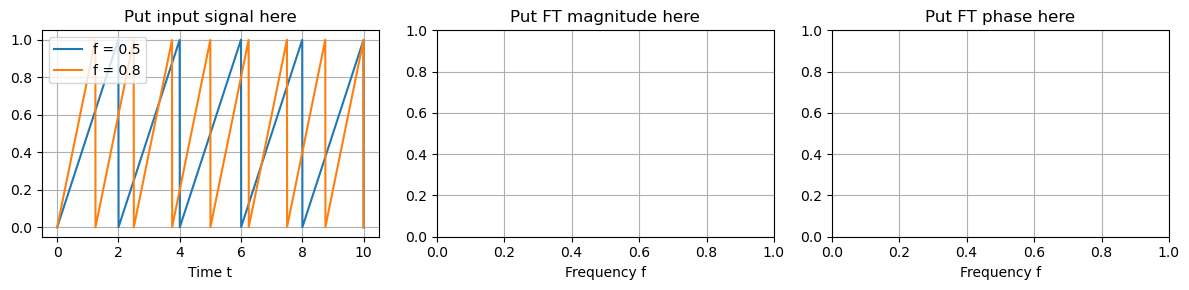

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [23]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



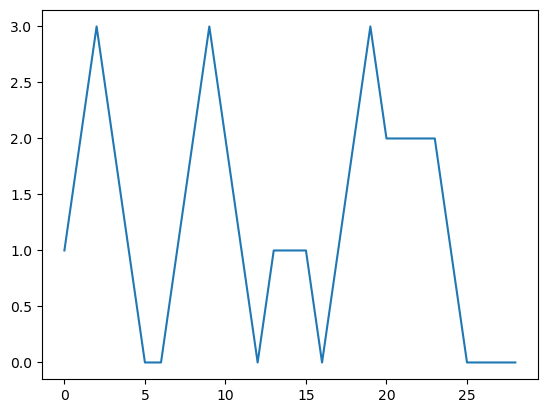

In [24]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [18]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [19]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

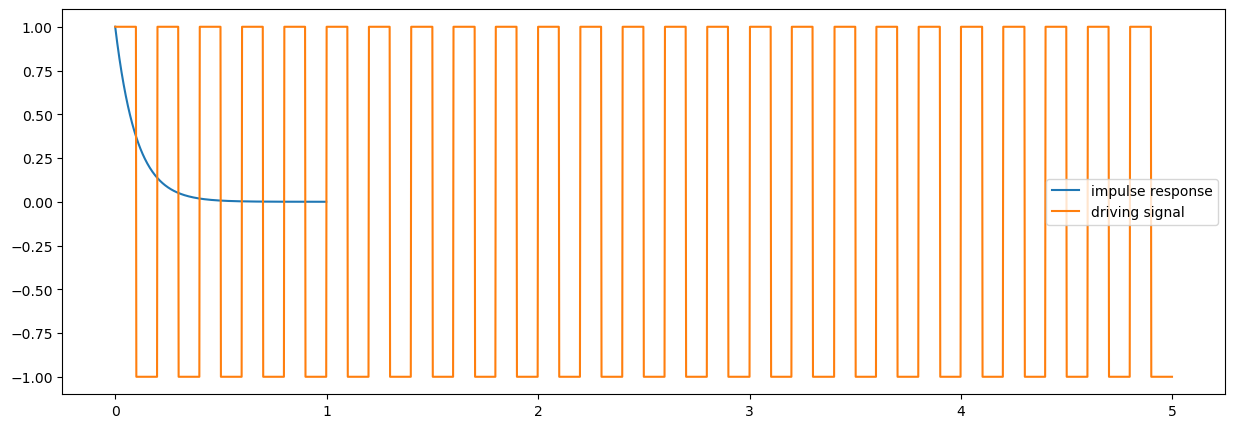

In [20]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [21]:
response = np.convolve(input_signal, h_t, mode = "same")

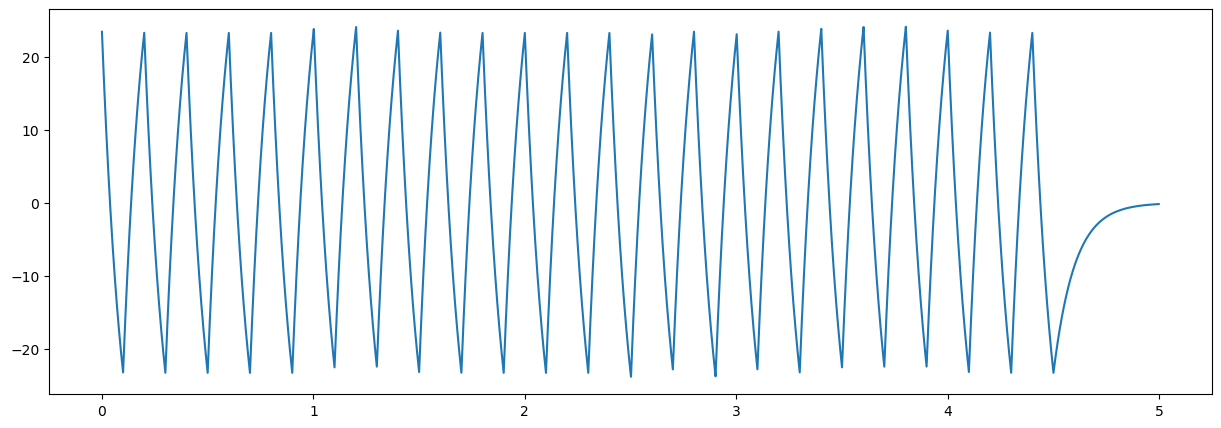

In [22]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [23]:
fourier_length = len(h_t) + len(input_signal) - 1

In [24]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [25]:
fourier_response = fourier_h*fourier_input 

In [26]:
response = np.real(np.fft.ifft(fourier_response))

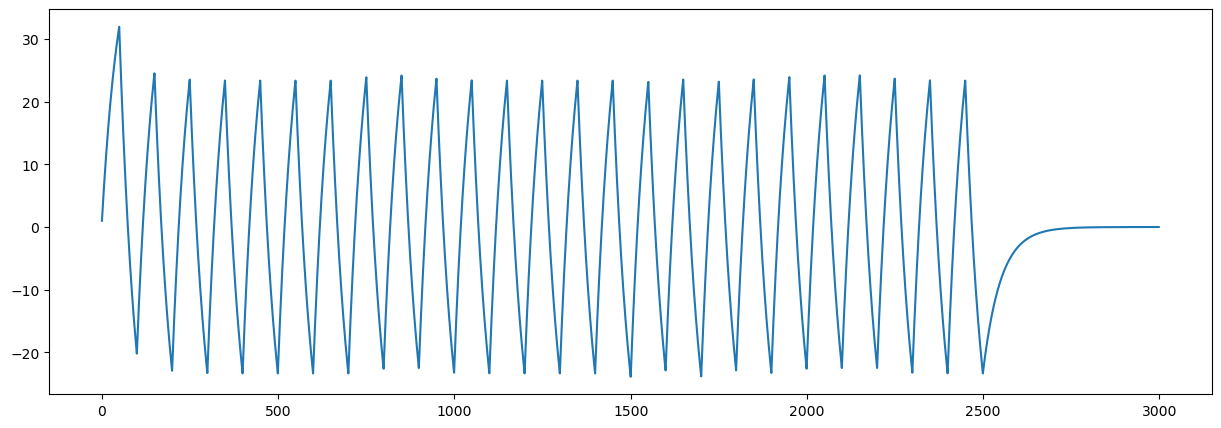

In [27]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)